# 03 · Tier 2: NLTK + Naive Bayes

**How it works.**
1. Each comment is turned into a list of **tokens** (words) using the Taglish cleaning from notebook 01:
   spellings fixed, emoji → words, laughter → `haha`, and **negation marking** (the 2 words after
   *hindi / wala / huwag / not* get a `NEG_` prefix, so *hindi magaling* → `hindi NEG_magaling`).
2. **Features** = which of the 3,000 most common training words appear in the comment
   (`{"galing": True, "lupet": True, ...}`), the same bag-of-words approach as the airline-tweets reference.
3. **NLTK's `NaiveBayesClassifier`** learns from the 700 training comments how likely each word is in
   each class. For a new comment it multiplies those probabilities and picks the most likely class.
   It is "naive" because it treats every word as independent of the others.

Install once: `pip install nltk` (no extra downloads are needed for this notebook).

In [1]:
import sys, pathlib
NB_DIR = pathlib.Path.cwd().resolve()
if NB_DIR.name != "notebooks":        # Jupyter was started in the repo root instead of notebooks/
    NB_DIR = NB_DIR / "notebooks"
ROOT = NB_DIR.parent                  # repo root (data/, results/, prompts.md ...)
sys.path.insert(0, str(NB_DIR))       # so "from src import ..." finds notebooks/src/

import pickle
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk import NaiveBayesClassifier, FreqDist
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score

from src import config, data, evaluate as ev
from src.profanity import mask, mask_frame     # curse words are masked in everything shown
from src.cleaning import normalize, tokenize

train, test = data.load_split()
hard = data.load_hard_cases()
print("NLTK", nltk.__version__, "|", len(train), "train |", len(test), "test")

NLTK 3.10.4 | 700 train | 300 test


In [2]:
def train_nb(token_lists, labels, vocab_size=3000):
    """Train NLTK Naive Bayes on bag-of-words features. Returns (classifier, feature function, vocabulary)."""
    vocab = {w for w, _ in FreqDist(w for ts in token_lists for w in ts).most_common(vocab_size)}
    def features(tokens):
        return {w: True for w in set(tokens) if w in vocab}
    clf = NaiveBayesClassifier.train([(features(ts), y) for ts, y in zip(token_lists, labels)])
    return clf, features, vocab

example = "Hindi naman talaga magaling si sheyee, pabuhat lng 😂"
print("with stopwords   :", tokenize(normalize(example), drop_stopwords=False))
print("stopwords removed:", tokenize(normalize(example)))

with stopwords   : ['hindi', 'naman', 'talaga', 'NEG_magaling', 'si', 'NEG_shehyee', 'pabuhat', 'lang', 'haha']
stopwords removed: ['hindi', 'NEG_magaling', 'NEG_shehyee', 'pabuhat', 'haha']


## 1. Which preprocessing works best? (5-fold cross-validation on the **training set only**)

The test set stays untouched until the final model is chosen.

In [3]:
variants = {
    "raw text (lowercase, split on spaces)": lambda r: r["text_clean"].lower().split(),
    "normalised": lambda r: r["text_norm"].split(),
    "normalised + NEG_": lambda r: tokenize(r["text_norm"], drop_stopwords=False),
    "normalised + NEG_ + stopwords removed": lambda r: tokenize(r["text_norm"]),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.SEED)
rows = []
for name, to_tokens in variants.items():
    scores = []
    for tr_idx, va_idx in cv.split(train, train["label"]):
        tr, va = train.iloc[tr_idx], train.iloc[va_idx]
        clf, feats, _ = train_nb([to_tokens(r) for _, r in tr.iterrows()], tr["label"])
        pred = [clf.classify(feats(to_tokens(r))) for _, r in va.iterrows()]
        scores.append(f1_score(va["label"], pred, average="macro"))
    rows.append({"preprocessing": name, "cv_macro_f1": sum(scores) / len(scores)})
pd.DataFrame(rows).set_index("preprocessing").round(3)

,cv_macro_f1
preprocessing,
"raw text (lowercase, split on spaces)",0.567
normalised,0.592
normalised + NEG_,0.583
normalised + NEG_ + stopwords removed,0.616


- Normalising the Taglish text (spelling map, emoji → words, laughter, phrases) helps over raw text.
- With word-presence features, **removing stopwords helps**: common words like *ang, ng, sa, mga* appear in
  every class, and Naive Bayes counts each of them as evidence, which adds noise.
- The final model uses **normalised + NEG_ + stopwords removed**, with the 3,000 most common words.

## 2. Train the final model on all 700 training comments

In [4]:
MODEL_NAME = "NLTK + Naive Bayes"

def to_tokens(text):
    """raw comment -> Taglish-normalised tokens with NEG_ marking, stopwords removed"""
    return tokenize(normalize(text))

nb_clf, nb_features, nb_vocab = train_nb([to_tokens(t) for t in train["text"]], train["label"])

# save the trained model so it can be reused without retraining
with open(config.RESULTS / "nltk_naive_bayes.pickle", "wb") as f:
    pickle.dump({"classifier": nb_clf, "vocabulary": sorted(nb_vocab)}, f)
print(f"trained on {len(train)} comments, {len(nb_vocab)} words in the vocabulary")
print("saved to results/nltk_naive_bayes.pickle")

trained on 700 comments, 2283 words in the vocabulary
saved to results/nltk_naive_bayes.pickle


## 3. Scores on the fixed 300-comment test set

== NLTK + Naive Bayes ==
              precision    recall  f1-score   support

    negative      0.651     0.855     0.739       131
     neutral      0.676     0.347     0.459        72
    positive      0.736     0.691     0.713        97

    accuracy                          0.680       300
   macro avg      0.688     0.631     0.637       300
weighted avg      0.685     0.680     0.663       300



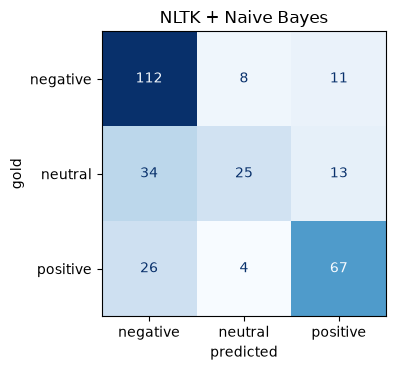

{'model': 'NLTK + Naive Bayes',
 'tier': '2 classic ML',
 'accuracy': 0.68,
 'macro_f1': 0.6369,
 'hard_acc': 0.5667,
 'sec_per_1k': 0.1381,
 'cost_per_1k_usd': 0.0}

In [5]:
def nb_predict(texts):
    return [nb_clf.classify(nb_features(to_tokens(t))) for t in texts]

pred_nb, sec_nb = ev.timed_predict(nb_predict, test["text"])      # timing includes cleaning
hard_nb = nb_predict(hard["text"])
ev.report(test["label"], pred_nb, MODEL_NAME)
ev.plot_confusion(test["label"], pred_nb, MODEL_NAME)
plt.show()
row = ev.save_run(MODEL_NAME, "2 classic ML", test, pred_nb, hard, hard_nb, sec_nb)
{k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()}

## 4. What did the model learn?

For each class, the words that are most likely in that class compared with the other two classes
(the same idea as NLTK's `show_most_informative_features`, with curse words masked).

In [6]:
labels = sorted(nb_clf.labels())
# P(word appears | class) for every vocabulary word and class
p_word = pd.DataFrame({lab: {w: nb_clf._feature_probdist[lab, w].prob(True) for w in nb_vocab}
                       for lab in labels})
top = {}
for lab in labels:
    others = p_word.drop(columns=lab).max(axis=1)
    lift = (p_word[lab] / others).sort_values(ascending=False)   # x times more likely in this class
    top[lab] = [f"{mask(w)} ({r:.1f}x)" for w, r in lift.head(15).items()]
pd.DataFrame(top)

,negative,neutral,positive
0,b**o (27.2x),whos (14.9x),lupet (17.0x)
1,g**o (19.4x),intro (12.2x),nice (14.0x)
2,t***a (18.3x),title (9.5x),galing (10.5x)
3,pikon (13.9x),english (9.5x),lakas (8.4x)
4,ina (9.4x),nanood (6.8x),fire (8.1x)
5,yabang (9.1x),kelan (6.8x),strong (8.1x)
6,ehh (7.2x),natin (6.8x),classic (7.5x)
7,u**l (7.2x),not (6.8x),finals (6.6x)
8,NEG_team_la (6.1x),pakinggan (6.8x),views (6.6x)
9,sad (6.1x),ahon (6.8x),solid (5.2x)


## 5. Hard cases

In [7]:
mask_frame(pd.DataFrame({"text": hard["text"], "gold": hard["label"], "NB": hard_nb,
                         "phenomenon": hard["phenomenon"]}))

,text,gold,NB,phenomenon
0,Hindi magaling si Loonie dito.,negative,negative,negation
1,Hindi naman pangit yung laban eh.,positive,negative,negation
2,Walang kwenta yung rebuttal nila.,negative,negative,negation
3,Wala akong masabi sa galing ni Smugglaz.,positive,negative,negation
4,T**g i*a ang lupet ng bara ni Abra!,positive,positive,profanity_as_praise
5,"P*******a, ang bangis talaga ng round 3!",positive,negative,profanity_as_praise
6,"G**o, pinakasolid na dos por dos 'to.",positive,negative,profanity_as_praise
7,"Wow, ang galing mag-choke ni Shehyee. Idol tal...",negative,positive,sarcasm
8,"Ang husay naman ng judges, 7-0 agad. Sobrang f...",negative,negative,sarcasm
9,Ganda ng laban sana kaso luto.,negative,negative,contrast
